# Group model comparison

Compare the six implemented classifiers on their saved **80,000-row development out-of-fold (OOF) predictions**: FT-Transformer, CatBoost, XGBoost, LightGBM, EBM and TabNet. Each employee is scored by a model whose outer training data excludes that employee's validation fold.

**Pooled Average Precision (AP)** is the primary group ranking metric. Mean fold AP and standard deviation describe stability. ROC-AUC, Brier score, calibration error and threshold metrics provide supporting evidence. A numerical leader does not automatically become a frozen final model.

Run All loads completed evidence and regenerates aggregate comparison outputs. It does not train models, require a GPU, load serialized model weights or evaluate the formal 20,000-row holdout. Inputs are selected by `configs/analysis_registry.yaml`, rather than whichever experiment happens to be newest.

## 1. Setup and project paths

Resolve paths from the repository root so this notebook runs from its own directory or the project root. Reuse the shared metric and validation helpers used by the other group analyses.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_curve

ROOT = next(
    (candidate for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (candidate / "configs/analysis_registry.yaml").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the Employee Resignation Prediction project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.inputs import load_group_inputs
from src.evaluation.oof_validation import validate_oof_predictions
from src.evaluation.metrics import calculate_binary_metrics
from src.evaluation.calibration import expected_calibration_error

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
out = ROOT / "results/comparison"
print(f"Project root: {ROOT}")

Project root: D:\Employee_Resignation_Prediction


## 2. Load and validate the canonical experiments

`load_group_inputs` verifies the frozen source and split checksums, then validates **every model** against development IDs, exact outer folds, source targets, model names and finite probabilities in [0, 1]. When present, `y_pred_0_5` must match a 0.50 cutoff. EBM additionally requires its config-bound formal artifact manifest. Invalid or missing evidence stops the notebook; there is no historical fallback.

The canonical FT input is the completed fixed-FT02 GPU run `FT02_20261003T025004Z`. It selects an epoch count using inner AP, then fits a fresh model on the inner-training rows. Its `tuning_complete=False` means no multi-candidate search was executed; its declared fixed-candidate evaluation is complete. The other models have nested candidate selection, and their fitting protocols differ. These differences limit interpretation of small score gaps.

The canonical EBM input is `results/models/ebm/individual_IT25100429/`: three raw candidates participate in inner selection and their standardized pairs provide sensitivity evidence. Parent-directory EBM results and earlier FT experiments remain historical.

In [2]:
registry, frames = load_group_inputs(ROOT)
expected_models = {"FT-Transformer", "CatBoost", "XGBoost", "LightGBM", "EBM", "TabNet"}
if set(frames) != expected_models:
    raise ValueError("The group comparison requires exactly the six declared headline models.")

reference = next(iter(frames.values()))
reference_ids = reference.Employee_ID.to_numpy()
reference_y = reference.y_true.astype(int).to_numpy()
input_rows = []
for model, predictions in frames.items():
    if not np.array_equal(predictions.Employee_ID.to_numpy(), reference_ids):
        raise ValueError(f"{model}: IDs are not aligned after validation.")
    if not np.array_equal(predictions.y_true.astype(int).to_numpy(), reference_y):
        raise ValueError(f"{model}: targets are not aligned after validation.")
    entry = registry["models"][model]
    input_rows.append({
        "model": model,
        "oof_rows": len(predictions),
        "outer_folds": predictions.cv_fold.nunique(),
        "multi_candidate_tuning_complete": entry["tuning_complete"],
        "protocol": entry["protocol"],
        "canonical_input": entry["oof_path"],
    })
input_inventory = pd.DataFrame(input_rows)
display(input_inventory)

target_counts = pd.Series(reference_y, name="Resigned").value_counts().sort_index()
prevalence = float(reference_y.mean())
display(target_counts.rename_axis("Resigned").to_frame("development_rows"))
print(f"Aligned OOF shape per model: {reference.shape}; no comparison rows dropped.")
print(f"Positive prevalence: {prevalence:.2%}; negative-to-positive ratio: {target_counts[0] / target_counts[1]:.2f}:1.")
print("Class imbalance: original OOF rows are retained. Weighting belongs to the recorded training protocols; no resampling here.")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,model,oof_rows,outer_folds,multi_candidate_tuning_complete,protocol,canonical_input
0,FT-Transformer,80000,5,False,fixed FT02 GPU 5-fold OOF; inner-AP epoch sele...,results/models/ft_transformer/reruns/FT02_2026...
1,CatBoost,80000,5,True,strict nested candidate selection,results/models/catboost/oof_predictions.csv
2,XGBoost,80000,5,True,Member 3 primary P1 one-hot; strict nested 8-c...,results/models/xgboost/oof_predictions.csv
3,LightGBM,80000,5,True,strict nested candidate selection,results/models/lightgbm/strict_nested/oof_pred...
4,EBM,80000,5,True,nested inner-AP selection among three raw cand...,results/models/ebm/individual_IT25100429/oof_p...
5,TabNet,80000,5,True,strict nested candidate selection,results/models/tabnet/oof_predictions.csv


,development_rows
Resigned,
0,71992
1,8008


Aligned OOF shape per model: (80000, 6); no comparison rows dropped.
Positive prevalence: 10.01%; negative-to-positive ratio: 8.99:1.
Class imbalance: original OOF rows are retained. Weighting belongs to the recorded training protocols; no resampling here.


## 3. Pooled metrics and outer-fold stability

AP summarizes precision across recall levels and is appropriate for the roughly 10% positive class. The positive prevalence is a constant-score/no-skill reference. AP here uses scikit-learn's Average Precision definition, not trapezoidal PR area. **Pooled AP** evaluates all development predictions together; **mean fold AP** averages five separately computed scores. They can rank models differently because AP is nonlinear and score scales can differ between fold models.

ROC-AUC near 0.50 suggests weak discrimination. Lower Brier score measures better squared probability error, while ECE uses ten equal-width calibration bins and depends on that binning. Small Brier or ECE does not establish useful ranking: nearly constant probabilities around prevalence can score well.

Fold SD is descriptive variation across the five saved folds. It is not a confidence interval or a significance test; overlapping training partitions prevent treating the folds as independent experiments.

In [3]:
rows, fold_rows, classification_rows = [], [], []
for model, predictions in frames.items():
    y = predictions.y_true.astype(int).to_numpy()
    probability = predictions.y_probability.astype(float).to_numpy()
    metrics = calculate_binary_metrics(y, probability, threshold=0.50)

    # Searching thresholds on these same OOF labels gives a descriptive maximum,
    # not an independently validated operating threshold.
    precision, recall, thresholds = precision_recall_curve(y, probability)
    denominator = precision[:-1] + recall[:-1]
    threshold_f1 = np.divide(
        2 * precision[:-1] * recall[:-1], denominator,
        out=np.zeros_like(thresholds), where=denominator > 0,
    )
    best_index = int(np.argmax(threshold_f1))
    best_threshold = float(thresholds[best_index])
    best_metrics = calculate_binary_metrics(y, probability, threshold=best_threshold)
    rows.append({
        "model": model,
        "protocol": registry["models"][model]["protocol"],
        "tuning_complete": registry["models"][model]["tuning_complete"],
        "pooled_average_precision": metrics["average_precision"],
        "pooled_roc_auc": metrics["roc_auc"],
        "brier_score": metrics["brier_score"],
        "ece_10_bins": expected_calibration_error(y, probability, 10),
        "f1_at_0_5": metrics["f1"],
        "f1_max_oof": best_metrics["f1"],
        "f1_max_threshold": best_threshold,
    })
    classification_rows.append({
        "model": model,
        **{key: metrics[key] for key in ["precision", "recall", "f1", "balanced_accuracy", "accuracy", "predicted_positive_rate"]},
    })
    for fold, subset in predictions.groupby("cv_fold", sort=True):
        fold_metrics = calculate_binary_metrics(subset.y_true, subset.y_probability)
        fold_rows.append({
            "model": model, "cv_fold": int(fold),
            **{key: fold_metrics[key] for key in ["average_precision", "roc_auc", "brier_score"]},
        })

folds = pd.DataFrame(fold_rows)
stability = folds.groupby("model").agg(
    cv_ap_mean=("average_precision", "mean"),
    cv_ap_sd=("average_precision", "std"),
    cv_roc_mean=("roc_auc", "mean"),
    cv_roc_sd=("roc_auc", "std"),
).reset_index()
comparison = pd.DataFrame(rows).merge(stability, on="model", validate="one_to_one")
comparison = comparison.sort_values("pooled_average_precision", ascending=False).reset_index(drop=True)
comparison["ap_uplift_over_prevalence"] = comparison.pooled_average_precision - prevalence

display(comparison[[
    "model", "pooled_average_precision", "ap_uplift_over_prevalence", "cv_ap_mean", "cv_ap_sd",
    "pooled_roc_auc", "brier_score", "ece_10_bins",
]])
display(folds.pivot(index="model", columns="cv_fold", values="average_precision").loc[comparison.model])

,model,pooled_average_precision,ap_uplift_over_prevalence,cv_ap_mean,cv_ap_sd,pooled_roc_auc,brier_score,ece_10_bins
0,XGBoost,0.101181,0.001081,0.101643,0.000990,0.502471,0.175329,0.227166
1,LightGBM,0.100153,0.000053,0.100202,0.002446,0.498740,0.180215,0.234650
2,TabNet,0.099965,-0.000135,0.101700,0.003876,0.499317,0.186177,0.240548
3,FT-Transformer,0.099842,-0.000258,0.100396,0.001809,0.498905,0.247200,0.395671
4,CatBoost,0.099346,-0.000754,0.100690,0.002784,0.500155,0.210753,0.313725
5,EBM,0.099000,-0.001100,0.099558,0.002073,0.495976,0.090109,0.003337


cv_fold,1,2,3,4,5
model,,,,,
XGBoost,0.100518,0.101290,0.101176,0.103077,0.102152
LightGBM,0.102428,0.100170,0.101850,0.100389,0.096173
TabNet,0.097812,0.102024,0.100511,0.108087,0.100067
FT-Transformer,0.097494,0.101310,0.101885,0.101510,0.099781
CatBoost,0.100165,0.104468,0.097033,0.099669,0.102114
EBM,0.096220,0.101301,0.101141,0.099062,0.100064


## 4. Dummy baseline references

Compare the headline models with the required saved Dummy classifiers on the same development IDs and folds. The prior baseline estimates prevalence from each outer training fold; its pooled AP can differ slightly from the overall prevalence. The most-frequent baseline provides constant negative predictions. Approximately 90% accuracy alone can therefore represent zero resignation detection.

Baseline IDs, labels, probabilities and fold assignments are validated before scoring. They remain reference rows rather than additional headline models in the six-model ranking.

In [4]:
split_registry = pd.read_csv(ROOT / "data/processed/split_registry.csv")
source_targets = reference[["Employee_ID", "y_true"]].rename(columns={"y_true": "Resigned"})
baseline_rows = []
for name, filename in [
    ("Dummy Prior", "dummy_prior_oof_predictions.csv"),
    ("Dummy Most Frequent", "dummy_most_frequent_oof_predictions.csv"),
]:
    predictions = pd.read_csv(ROOT / "results/baselines" / filename)
    validate_oof_predictions(predictions, split_registry, source_data=source_targets, expected_model_name=name)
    metrics = calculate_binary_metrics(predictions.y_true, predictions.y_probability)
    baseline_rows.append({
        "model": name,
        **{key: metrics[key] for key in ["average_precision", "roc_auc", "brier_score", "accuracy", "recall", "f1"]},
    })
baselines = pd.DataFrame(baseline_rows)
display(baselines)
print(f"Constant prevalence-probability reference: AP={prevalence:.6f}; Brier={prevalence * (1 - prevalence):.6f}.")

,model,average_precision,roc_auc,brier_score,accuracy,recall,f1
0,Dummy Prior,0.100085,0.499917,0.090080,0.899900,0.000000,0.000000
1,Dummy Most Frequent,0.100100,0.500000,0.100100,0.899900,0.000000,0.000000


Constant prevalence-probability reference: AP=0.100100; Brier=0.090080.


## 5. Comparison figures

The first two plots show pooled AP against prevalence and ROC-AUC against 0.50. The third uses a **zoomed AP axis** to inspect fold variation; markers are mean fold AP and error bars are one fold SD. These error bars do not quantify statistical significance, and the mean-fold figure does not change the pooled-AP ranking.

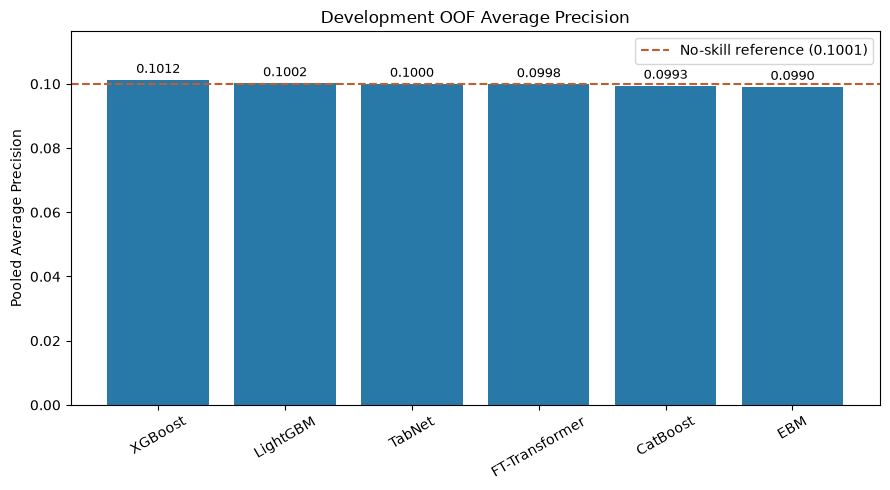

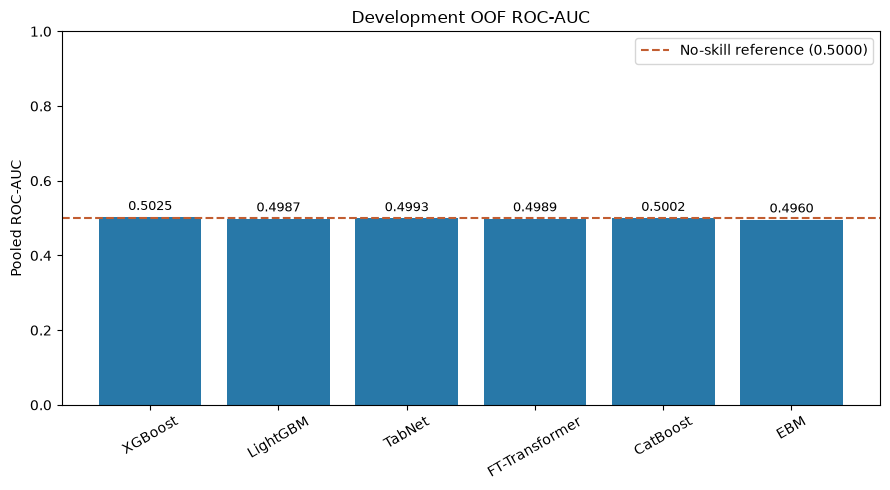

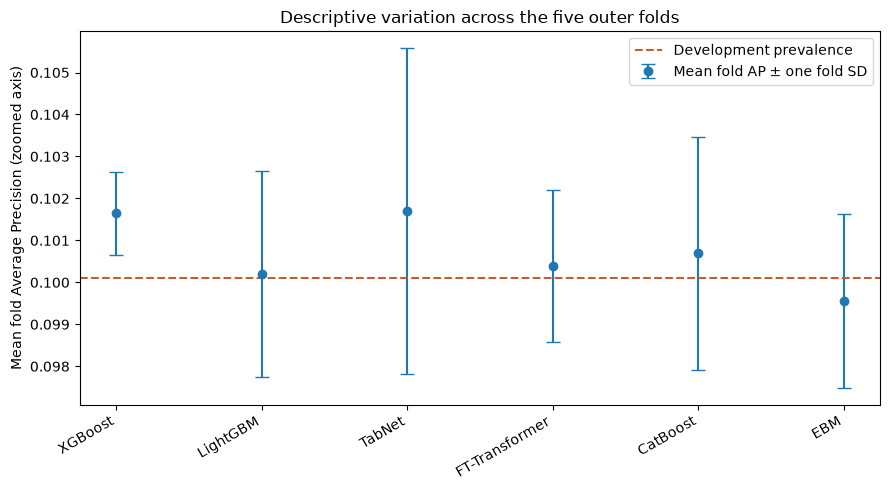

In [5]:
out.mkdir(parents=True, exist_ok=True)
figure_names = []
for column, reference_value, ylabel, title, filename in [
    ("pooled_average_precision", prevalence, "Pooled Average Precision", "Development OOF Average Precision", "figure_01_average_precision_comparison.png"),
    ("pooled_roc_auc", 0.50, "Pooled ROC-AUC", "Development OOF ROC-AUC", "figure_02_roc_auc_comparison.png"),
]:
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(comparison.model, comparison[column], color="#2878A8")
    ax.axhline(reference_value, color="#C25D31", linestyle="--", label=f"No-skill reference ({reference_value:.4f})")
    ax.bar_label(bars, labels=[f"{value:.4f}" for value in comparison[column]], padding=3, fontsize=9)
    ax.set_ylim(0, 1 if column == "pooled_roc_auc" else max(comparison[column].max(), prevalence) * 1.15)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=30)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / filename, dpi=160)
    plt.show()
    plt.close(fig)
    figure_names.append(filename)

fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(comparison))
ax.errorbar(positions, comparison.cv_ap_mean, yerr=comparison.cv_ap_sd, fmt="o", capsize=5, label="Mean fold AP ± one fold SD")
ax.axhline(prevalence, color="#C25D31", linestyle="--", label="Development prevalence")
ax.set_xticks(positions, comparison.model, rotation=30, ha="right")
ax.set_ylabel("Mean fold Average Precision (zoomed axis)")
ax.set_title("Descriptive variation across the five outer folds")
ax.legend()
fig.tight_layout()
filename = "figure_03_fold_ap_stability.png"
fig.savefig(out / filename, dpi=160)
plt.show()
plt.close(fig)
figure_names.append(filename)

## 6. Threshold diagnostics

Precision, recall, F1, balanced accuracy and accuracy depend on a cutoff. The 0.50 table describes the saved probability scales; class-weighted training can change those scales. It does not replace AP-based ranking or a separate calibration assessment.

The maximum-F1 table searches thresholds on the same pooled OOF outcomes used to report F1. Its maximum is optimistic for threshold selection and is shown **only as a development diagnostic**. No threshold is frozen or applied to the formal holdout. A separate validation procedure would be required before claiming performance at a selected operating threshold.

In [6]:
classification = pd.DataFrame(classification_rows).set_index("model").loc[comparison.model].reset_index()
print("Metrics at the default 0.50 cutoff:")
display(classification)
print("Descriptive maximum F1 on the same development OOF labels:")
display(comparison[["model", "f1_at_0_5", "f1_max_oof", "f1_max_threshold"]])

Metrics at the default 0.50 cutoff:


,model,precision,recall,f1,balanced_accuracy,accuracy,predicted_positive_rate
0,XGBoost,0.102662,0.195055,0.134522,0.502704,0.748762,0.190188
1,LightGBM,0.099190,0.262862,0.144030,0.498659,0.687250,0.265275
2,TabNet,0.098593,0.289585,0.147103,0.497540,0.663863,0.294013
3,FT-Transformer,0.099916,0.458417,0.164071,0.499530,0.532412,0.459263
4,CatBoost,0.098728,0.253871,0.142168,0.498039,0.693325,0.257400
5,EBM,0.000000,0.000000,0.000000,0.500000,0.899900,0.000000


Descriptive maximum F1 on the same development OOF labels:


,model,f1_at_0_5,f1_max_oof,f1_max_threshold
0,XGBoost,0.134522,0.182479,0.084618
1,LightGBM,0.144030,0.182125,0.076155
2,TabNet,0.147103,0.182062,0.079762
3,FT-Transformer,0.164071,0.181990,0.383656
4,CatBoost,0.142168,0.181988,0.103214
5,EBM,0.000000,0.181990,0.071095


## 7. Selection decision and interpretation

Report the numerical leader transparently, then compare its uplift with prevalence, fold variation and protocol differences. Calibration quality and discrimination answer different questions. Near-no-skill results do not justify choosing a model for real employee decisions or using the untouched holdout to search for a better-looking winner.

This notebook records the development conclusion. Final model, calibrator and threshold freeze—and the one-time final holdout evaluation—remain separate steps.

In [7]:
leader = comparison.iloc[0]
mean_fold_leader = comparison.sort_values("cv_ap_mean", ascending=False).iloc[0]
best_brier = comparison.sort_values("brier_score").iloc[0]
summary = {
    "development_rows": int(len(reference_ids)),
    "positive_prevalence": prevalence,
    "ranking_leader": str(leader.model),
    "leader_pooled_average_precision": float(leader.pooled_average_precision),
    "leader_ap_uplift_over_prevalence": float(leader.ap_uplift_over_prevalence),
    "final_model_frozen": False,
    "reason_not_frozen": "All models remain near the no-skill baseline; candidate-selection and final-fit protocols differ across models.",
    "formal_holdout_accessed": False,
}
display(Markdown(
    f"**Pooled-AP leader: {leader.model}**, AP **{leader.pooled_average_precision:.6f}** "
    f"versus prevalence **{prevalence:.6f}**. The absolute uplift is "
    f"**{leader.ap_uplift_over_prevalence:.6f}** ({100 * leader.ap_uplift_over_prevalence:.3f} percentage points). "
    f"The mean-fold AP leader is **{mean_fold_leader.model}** "
    f"({mean_fold_leader.cv_ap_mean:.6f}); this illustrates why the aggregation rule matters.\n\n"
    f"**{best_brier.model}** has the lowest headline Brier score ({best_brier.brier_score:.6f}), "
    "which does not establish useful discrimination. All six results remain close to no-skill. "
    "Small differences and unequal training protocols do not establish a reliably superior model. "
    "**No final model is frozen; the formal holdout remains locked.**"
))
display(pd.DataFrame([summary]))

**Pooled-AP leader: XGBoost**, AP **0.101181** versus prevalence **0.100100**. The absolute uplift is **0.001081** (0.108 percentage points). The mean-fold AP leader is **TabNet** (0.101700); this illustrates why the aggregation rule matters.

**EBM** has the lowest headline Brier score (0.090109), which does not establish useful discrimination. All six results remain close to no-skill. Small differences and unequal training protocols do not establish a reliably superior model. **No final model is frozen; the formal holdout remains locked.**

,development_rows,positive_prevalence,ranking_leader,leader_pooled_average_precision,leader_ap_uplift_over_prevalence,final_model_frozen,reason_not_frozen,formal_holdout_accessed
0,80000,0.100100,XGBoost,0.101181,0.001081,False,All models remain near the no-skill baseline; ...,False


## 8. Export and completion checks

Regenerate aggregate results in `results/comparison/`: the six-model comparison, 30 fold-metric rows, two Dummy baseline rows, the selection summary and three figures. The established `model_comparison.csv` and `comparison_summary.json` fields remain compatible with downstream group analyses. No employee-level predictions, model weights or training outputs are overwritten.

Re-read the exported tables and check their metrics against the in-memory calculations before declaring this notebook complete.

In [8]:
comparison.to_csv(out / "model_comparison.csv", index=False)
folds.to_csv(out / "fold_metrics_long.csv", index=False)
baselines.to_csv(out / "baseline_comparison.csv", index=False)
(out / "comparison_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

saved_comparison = pd.read_csv(out / "model_comparison.csv")
saved_folds = pd.read_csv(out / "fold_metrics_long.csv")
saved_baselines = pd.read_csv(out / "baseline_comparison.csv")
assert set(saved_comparison.model) == expected_models
assert len(saved_comparison) == 6 and len(saved_folds) == 30
assert saved_folds.groupby("model").cv_fold.nunique().eq(5).all()
pd.testing.assert_frame_equal(saved_comparison, comparison, check_dtype=False, rtol=1e-12, atol=1e-12)
pd.testing.assert_frame_equal(saved_folds, folds, check_dtype=False, rtol=1e-12, atol=1e-12)
pd.testing.assert_frame_equal(saved_baselines, baselines, check_dtype=False, rtol=1e-12, atol=1e-12)
assert json.loads((out / "comparison_summary.json").read_text()) == summary

output_files = ["model_comparison.csv", "fold_metrics_long.csv", "baseline_comparison.csv", "comparison_summary.json", *figure_names]
assert all((out / filename).is_file() for filename in output_files)
display(pd.DataFrame({"completed_output": [str((out / filename).relative_to(ROOT)) for filename in output_files]}))
print("Complete: six validated canonical models, two validated baselines, five outer folds per model.")
print("Aggregate outputs verified; no model training or formal holdout evaluation performed.")

,completed_output
0,results\comparison\model_comparison.csv
1,results\comparison\fold_metrics_long.csv
2,results\comparison\baseline_comparison.csv
3,results\comparison\comparison_summary.json
4,results\comparison\figure_01_average_precision...
5,results\comparison\figure_02_roc_auc_compariso...
6,results\comparison\figure_03_fold_ap_stability...


Complete: six validated canonical models, two validated baselines, five outer folds per model.
Aggregate outputs verified; no model training or formal holdout evaluation performed.
